In [1]:

import os
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import hog
from skimage.transform import rotate
from skimage.util import random_noise

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
random.seed(42)
np.random.seed(42)

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

import os

# Check common locations for the dataset
possible_paths = [
    r'C:\Users\alghad\Downloads\archive\dogs_vs_cats\train',
    r'C:\Users\Asus\Downloads\archive\dogs_vs_cats\train',
    os.path.join(os.path.expanduser('~'), 'Downloads', 'archive', 'dogs_vs_cats', 'train'),
    os.path.join(os.path.expanduser('~'), 'OneDrive', 'Desktop', 'PatternRecognition')
]

for path in possible_paths:
    print(f"{'FOUND' if os.path.isdir(path) else 'NOT FOUND'}: {path}")

print("\nYour Windows home directory:")
print(os.path.expanduser('~'))


NOT FOUND: C:\Users\alghad\Downloads\archive\dogs_vs_cats\train
NOT FOUND: C:\Users\Asus\Downloads\archive\dogs_vs_cats\train
NOT FOUND: C:\Users\Asus\Downloads\archive\dogs_vs_cats\train
FOUND: C:\Users\Asus\OneDrive\Desktop\PatternRecognition

Your Windows home directory:
C:\Users\Asus


In [4]:

import os

train_dir = r'C:\Users\Asus\OneDrive\Desktop\PatternRecognition'

# Display files and folders inside the project directory
print("Contents of PatternRecognition:\n")

for item in os.listdir(train_dir):
    full_path = os.path.join(train_dir, item)

    if os.path.isdir(full_path):
        print(f"[FOLDER] {item}")
    else:
        print(f"[FILE]   {item}")


Contents of PatternRecognition:

[FOLDER] .venv
[FILE]   Screenshot 2026-10-03 180016.png


Image loaded successfully!
Image dimensions: (454, 612, 3)


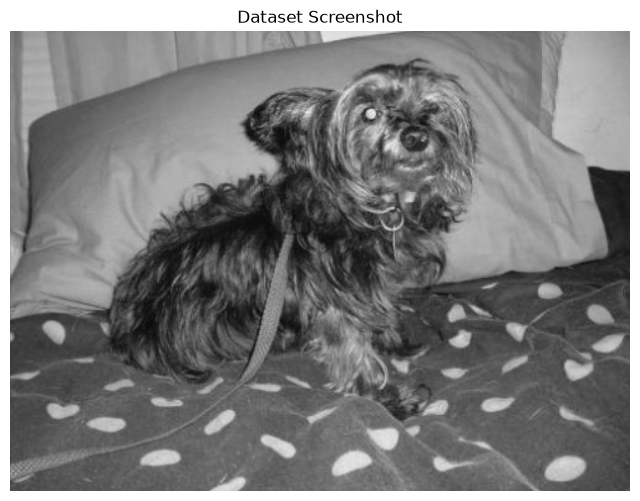

In [5]:

import os
import cv2
import matplotlib.pyplot as plt

train_dir = r'C:\Users\Asus\OneDrive\Desktop\PatternRecognition'

image_path = os.path.join(
    train_dir,
    'Screenshot 2026-10-03 180016.png'
)

img = cv2.imread(image_path)

if img is None:
    print("ERROR: Could not read the image.")
else:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    print("Image loaded successfully!")
    print("Image dimensions:", img.shape)
    
    plt.figure(figsize=(8, 6))
    plt.imshow(img_rgb)
    plt.title("Dataset Screenshot")
    plt.axis("off")
    plt.show()


In [6]:

import os
import urllib.request
import zipfile

# Dataset download URL
url = "https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip"

# Save everything inside your project folder
project_dir = r'C:\Users\Asus\OneDrive\Desktop\PatternRecognition'
zip_path = os.path.join(project_dir, "cats_and_dogs_filtered.zip")
extract_dir = os.path.join(project_dir, "dataset")

# Download the dataset if it is not already downloaded
if not os.path.exists(extract_dir):
    print("Downloading dataset... Please wait.")

    urllib.request.urlretrieve(url, zip_path)

    print("Download completed!")
    print("Extracting dataset...")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_dir)

    print("Extraction completed!")

else:
    print("Dataset folder already exists.")

# Show the extracted folders
for root, dirs, files in os.walk(extract_dir):
    if dirs:
        print("Folder:", root)
        print("Subfolders:", dirs)


Download completed!
Extracting dataset...
Extraction completed!
Folder: C:\Users\Asus\OneDrive\Desktop\PatternRecognition\dataset
Subfolders: ['cats_and_dogs_filtered']
Folder: C:\Users\Asus\OneDrive\Desktop\PatternRecognition\dataset\cats_and_dogs_filtered
Subfolders: ['train', 'validation']
Folder: C:\Users\Asus\OneDrive\Desktop\PatternRecognition\dataset\cats_and_dogs_filtered\train
Subfolders: ['cats', 'dogs']
Folder: C:\Users\Asus\OneDrive\Desktop\PatternRecognition\dataset\cats_and_dogs_filtered\validation
Subfolders: ['cats', 'dogs']


In [7]:

import os

project_dir = r'C:\Users\Asus\OneDrive\Desktop\PatternRecognition'

base_dir = os.path.join(
    project_dir, 'dataset', 'cats_and_dogs_filtered'
)

train_dir = os.path.join(base_dir, 'train')
validation_dir = os.path.join(base_dir, 'validation')

categories = ['dogs', 'cats']

for split_name, split_dir in [
    ('Training', train_dir),
    ('Validation', validation_dir)
]:
    print(f"\n{split_name} Dataset:")

    for category in categories:
        category_path = os.path.join(split_dir, category)
        image_count = len([
            f for f in os.listdir(category_path)
            if os.path.isfile(os.path.join(category_path, f))
        ])
        print(f"{category}: {image_count} images")



Training Dataset:
dogs: 1000 images
cats: 1000 images

Validation Dataset:
dogs: 500 images
cats: 500 images


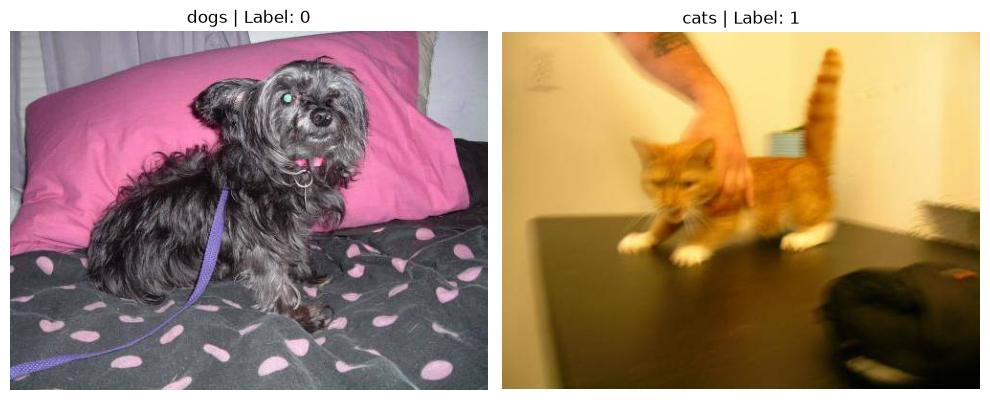

In [8]:

import os
import cv2
import matplotlib.pyplot as plt

categories = ['dogs', 'cats']
label_map = {'dogs': 0, 'cats': 1}

sample_images = []

for category in categories:
    category_path = os.path.join(train_dir, category)

    for filename in sorted(os.listdir(category_path)):
        image_path = os.path.join(category_path, filename)
        image = cv2.imread(image_path)

        if image is not None:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            sample_images.append((image, category))
            break

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (image, category) in zip(axes, sample_images):
    ax.imshow(image)
    ax.set_title(f'{category} | Label: {label_map[category]}')
    ax.axis('off')

plt.tight_layout()
plt.show()


In [9]:

from skimage.feature import hog
import numpy as np
import cv2
import os

def extract_hog_features(image):
    image = cv2.resize(image, (100, 100))
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=False
    )

    return features

sample_path = os.path.join(
    train_dir, 'dogs',
    os.listdir(os.path.join(train_dir, 'dogs'))[0]
)

sample_image = cv2.imread(sample_path)
hog_features = extract_hog_features(sample_image)

print("HOG extraction successful!")
print("Feature vector shape:", hog_features.shape)
print("Number of features:", len(hog_features))


HOG extraction successful!
Feature vector shape: (4356,)
Number of features: 4356


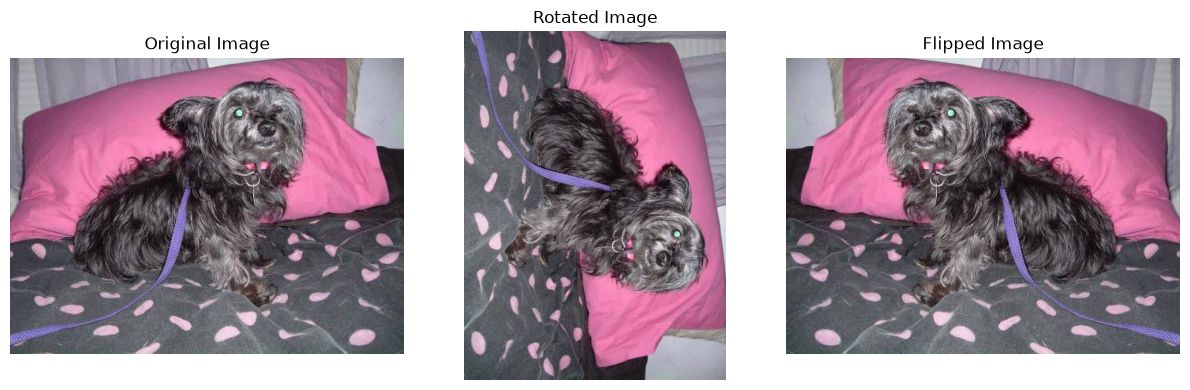

In [10]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load one training image
sample_path = os.path.join(
    train_dir,
    'dogs',
    os.listdir(os.path.join(train_dir, 'dogs'))[0]
)

image = cv2.imread(sample_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Apply data augmentation
rotated_image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
flipped_image = cv2.flip(image, 1)

# Display original and augmented images
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image)
axes[0].set_title("Original Image")

axes[1].imshow(rotated_image)
axes[1].set_title("Rotated Image")

axes[2].imshow(flipped_image)
axes[2].set_title("Flipped Image")

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()


In [12]:

import os
import cv2
import numpy as np

categories = ['dogs', 'cats']
label_map = {'dogs': 0, 'cats': 1}

X_train_images = []
y_train = []

for category in categories:
    category_path = os.path.join(train_dir, category)
    label = label_map[category]

    image_files = sorted(os.listdir(category_path))

    for filename in image_files:
        image_path = os.path.join(category_path, filename)
        image = cv2.imread(image_path)

        if image is None:
            continue

        image = cv2.resize(image, (100, 100))

        # Original image
        X_train_images.append(image)
        y_train.append(label)

        # Horizontal flip
        flipped = cv2.flip(image, 1)
        X_train_images.append(flipped)
        y_train.append(label)

        # Small rotation
        rotated = cv2.rotate(image, cv2.ROTATE_180)
        X_train_images.append(rotated)
        y_train.append(label)

X_train_images = np.array(X_train_images)
y_train = np.array(y_train)

print("Data augmentation completed!")
print("Training images shape:", X_train_images.shape)
print("Training labels shape:", y_train.shape)
print("Total training images:", len(X_train_images))


Data augmentation completed!
Training images shape: (6000, 100, 100, 3)
Training labels shape: (6000,)
Total training images: 6000


In [13]:

from skimage.feature import hog
import numpy as np
import cv2

def extract_hog_features(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=False
    )

    return features

X_train_features = []

for i, image in enumerate(X_train_images):
    features = extract_hog_features(image)
    X_train_features.append(features)

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1}/{len(X_train_images)} images")

X_train_features = np.array(X_train_features)

print("\nHOG extraction completed!")
print("Training features shape:", X_train_features.shape)
print("Training labels shape:", y_train.shape)


Processed 500/6000 images
Processed 1000/6000 images
Processed 1500/6000 images
Processed 2000/6000 images
Processed 2500/6000 images
Processed 3000/6000 images
Processed 3500/6000 images
Processed 4000/6000 images
Processed 4500/6000 images
Processed 5000/6000 images
Processed 5500/6000 images
Processed 6000/6000 images

HOG extraction completed!
Training features shape: (6000, 4356)
Training labels shape: (6000,)


In [14]:

X_val_features = []
y_val = []
X_val_images = []

for category in categories:
    category_path = os.path.join(validation_dir, category)
    label = label_map[category]

    image_files = sorted(os.listdir(category_path))

    for filename in image_files:
        image_path = os.path.join(category_path, filename)
        image = cv2.imread(image_path)

        if image is None:
            continue

        image = cv2.resize(image, (100, 100))

        # Keep images for later prediction visualization
        X_val_images.append(image.copy())

        # Extract HOG features
        features = extract_hog_features(image)
        X_val_features.append(features)

        y_val.append(label)

X_val_features = np.array(X_val_features)
y_val = np.array(y_val)
X_val_images = np.array(X_val_images)

print("Validation preparation completed!")
print("Validation features shape:", X_val_features.shape)
print("Validation labels shape:", y_val.shape)
print("Validation images shape:", X_val_images.shape)



Validation preparation completed!
Validation features shape: (1000, 4356)
Validation labels shape: (1000,)
Validation images shape: (1000, 100, 100, 3)


In [15]:

from sklearn.decomposition import PCA

# Create PCA with 200 components
pca = PCA(n_components=200, random_state=42)

# Fit only on training data
X_train_pca = pca.fit_transform(X_train_features)

# Transform validation data using the same PCA
X_val_pca = pca.transform(X_val_features)

print("PCA completed successfully!")
print("Original training shape:", X_train_features.shape)
print("Reduced training shape:", X_train_pca.shape)
print("Original validation shape:", X_val_features.shape)
print("Reduced validation shape:", X_val_pca.shape)

print(
    "Total explained variance:",
    round(np.sum(pca.explained_variance_ratio_), 4)
)


PCA completed successfully!
Original training shape: (6000, 4356)
Reduced training shape: (6000, 200)
Original validation shape: (1000, 4356)
Reduced validation shape: (1000, 200)
Total explained variance: 0.5594


In [16]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import time

# Create the SVM model
svm_model = SVC(
    kernel='rbf',
    C=10,
    gamma='scale',
    random_state=42
)

# Train the model
start_time = time.time()

svm_model.fit(X_train_pca, y_train)

training_time = time.time() - start_time

# Predict validation labels
y_pred_svm = svm_model.predict(X_val_pca)

# Calculate accuracy
svm_accuracy = accuracy_score(y_val, y_pred_svm)

print("SVM training completed!")
print(f"Training time: {training_time:.2f} seconds")
print(f"Validation Accuracy: {svm_accuracy * 100:.2f}%")


SVM training completed!
Training time: 3.32 seconds
Validation Accuracy: 71.50%


In [17]:

from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import time

# Standardize PCA features before SVM
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC())
])

param_distributions = {
    'svm__C': [0.1, 1, 10, 50, 100],
    'svm__kernel': ['rbf', 'linear'],
    'svm__gamma': ['scale', 'auto', 0.001, 0.01]
}

svm_search = RandomizedSearchCV(
    estimator=svm_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

start_time = time.time()

svm_search.fit(X_train_pca, y_train)

tuning_time = time.time() - start_time

best_svm = svm_search.best_estimator_
y_pred_svm_tuned = best_svm.predict(X_val_pca)

print("\nSVM tuning completed!")
print("Best parameters:", svm_search.best_params_)
print(f"Best CV Accuracy: {svm_search.best_score_ * 100:.2f}%")
print(f"Validation Accuracy: {accuracy_score(y_val, y_pred_svm_tuned) * 100:.2f}%")
print(f"Tuning time: {tuning_time:.2f} seconds")


Fitting 3 folds for each of 10 candidates, totalling 30 fits


KeyboardInterrupt: 